# 04b · Investigação dos KPIs
**Pergunta:** onde o CD está perdendo nível de serviço, dinheiro e produto — e por quê?
Cada seção parte de um indicador (OTIF, ruptura, lead time, dock-to-stock, perdas, acuracidade,
ocupação) e desce até a causa provável. Período: 01/11/2024 a 31/10/2026 (linhas de warm-up
anteriores são excluídas, ver 04a).

*EN summary: KPI deep-dive — OTIF decomposition, stockouts, peak-season backlog, suppliers,
dock-to-stock, cold chain, putaway errors, occupancy.*

In [1]:
import sys
sys.path.insert(0, "../src")
import pandas as pd
import matplotlib.pyplot as plt
from dcanalysis import q, save, savefig, log, ZONE_COLORS

NB = "04b"
INI = "2024-11-01"
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

## 1. OTIF: o problema é "in full" ou "on time"?
OTIF = pedido com ≥ 98% das unidades atendidas **e** entregue até a data prometida.
Decompor em In Full e On Time mostra qual das duas pernas puxa o indicador para baixo.

In [2]:
pedidos = q("""
    SELECT order_id, MIN(channel) AS channel, MIN(order_date) AS order_date,
           MIN(promised_date) AS promised_date, MIN(release_date) AS release_date,
           MIN(shipped_date) AS shipped_date, MIN(delivered_date) AS delivered_date,
           COUNT(*) AS n_linhas,
           SUM(qty_picked_units) * 1.0 / SUM(qty_ordered_units) AS pct_atendido
    FROM fact_order_line
    WHERE order_date >= :ini
    GROUP BY order_id""", ini=INI)
for c in ["order_date", "promised_date", "release_date", "shipped_date", "delivered_date"]:
    pedidos[c] = pd.to_datetime(pedidos[c])
pedidos["in_full"] = pedidos.pct_atendido >= 0.98
pedidos["on_time"] = pedidos.delivered_date <= pedidos.promised_date
pedidos["otif"] = pedidos.in_full & pedidos.on_time
pedidos["mes"] = pedidos.order_date.dt.to_period("M")

otif_canal = (pedidos.groupby("channel")
              .agg(pedidos=("order_id", "size"), linhas_por_pedido=("n_linhas", "mean"),
                   in_full=("in_full", "mean"), on_time=("on_time", "mean"), otif=("otif", "mean"))
              .round(3))
otif_canal

,pedidos,linhas_por_pedido,in_full,on_time,otif
channel,,,,,
B2B,36569,31.949,0.231,0.899,0.213
ECOM,84333,3.991,0.696,0.942,0.656


**Leitura:** no B2B o *on time* é razoável (~90%), mas o *in full* despenca (~23%). Com ~32 linhas
por pedido, basta uma ou duas linhas cortadas para o pedido inteiro sair "incompleto".
Ou seja, **o OTIF do B2B é um problema de ruptura de estoque, não de transporte.**

mes,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,...,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
in_full,46.3,58.3,76.1,58.9,37.9,44.7,56.8,48.0,52.8,62.2,...,56.4,59.2,48.4,61.4,52.1,56.3,55.9,62.5,55.9,48.3
on_time,98.0,97.5,97.6,98.1,98.0,98.0,98.6,97.9,97.7,98.2,...,58.1,98.0,98.1,96.5,97.8,98.0,98.0,97.9,97.6,97.1
otif,45.5,57.1,74.4,57.9,37.2,44.0,56.0,47.2,51.7,61.0,...,34.9,58.2,47.5,59.4,51.2,55.3,54.8,61.3,54.6,47.0


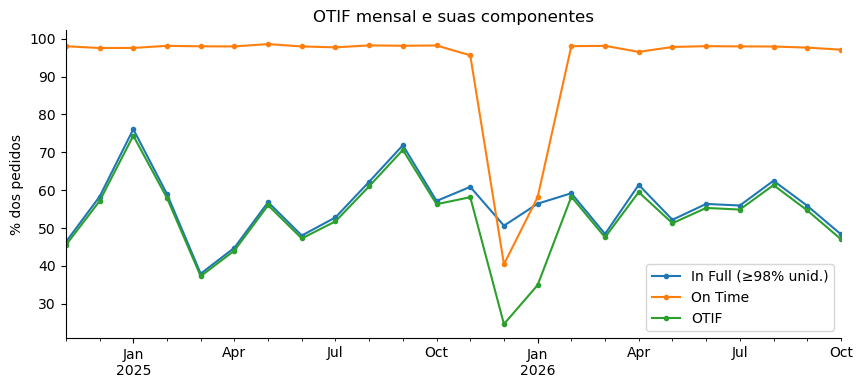

In [3]:
# Gráfico de linhas: evolução mensal das três medidas — linha é o melhor tipo para tendência no tempo.
mensal = pedidos.groupby("mes")[["in_full", "on_time", "otif"]].mean().mul(100)
fig, ax = plt.subplots()
mensal.plot(ax=ax, marker="o", ms=3)
ax.set_ylabel("% dos pedidos"); ax.set_xlabel(""); ax.set_title("OTIF mensal e suas componentes")
ax.legend(["In Full (≥98% unid.)", "On Time", "OTIF"])
savefig(fig, "04b_otif_mensal")
mensal.round(1).T

O *on time* fica estável em ~98% e **desaba em dez/2025 (40%) e jan/2026 (58%)**. A seção 3
investiga esse período.

## 2. Ruptura: onde estão as unidades cortadas?

In [4]:
linhas = q("""
    SELECT f.sku_id, s.zone, s.category, f.order_date,
           f.qty_ordered_units AS pedido, f.qty_picked_units AS separado
    FROM fact_order_line f JOIN dim_sku s ON s.sku_id = f.sku_id
    WHERE f.order_date >= :ini""", ini=INI)
linhas["cortado"] = linhas.pedido - linhas.separado

por_zona = linhas.groupby("zone")[["pedido", "cortado"]].sum()
por_zona["corte_pct"] = (100 * por_zona.cortado / por_zona.pedido).round(2)
print(por_zona)

# Concentração: quantos SKUs explicam 80% das unidades cortadas? (Pareto)
corte_sku = linhas.groupby("sku_id").cortado.sum().sort_values(ascending=False)
acum = corte_sku.cumsum() / corte_sku.sum()
n80 = int((acum <= 0.80).sum()) + 1
print(f"{n80} de {corte_sku.size} SKUs ({n80 / corte_sku.size:.0%}) concentram 80% das unidades cortadas")

           pedido  cortado  corte_pct
zone                                 
chilled  16202386   705539       4.35
dry      35764395  3340839       9.34
frozen    3184485    29245       0.92
70 de 599 SKUs (12%) concentram 80% das unidades cortadas


### 2.1 Promoções não comunicadas ao planejamento
Hipótese: quando o planejamento não sabe da promoção, não reforça o estoque e o SKU rompe.
Comparamos o fill rate do SKU **dentro** da janela da promoção, separando comunicadas × não comunicadas.

In [5]:
promo = q("SELECT * FROM aux_promotion")
promo["comunicada"] = promo.communicated_to_planning_date.notna() & \
                      (promo.communicated_to_planning_date <= promo.start_date)
# Junta cada linha de pedido com a promoção ativa do mesmo SKU naquele dia (se houver)
linhas["linha"] = range(len(linhas))          # identificador para saber quais linhas caem em promoção
lp = linhas.merge(promo[["sku_id", "start_date", "end_date", "comunicada"]], on="sku_id", how="inner")
lp = lp[(lp.order_date >= lp.start_date) & (lp.order_date <= lp.end_date)]
lp = lp.drop_duplicates("linha")              # se duas promoções se sobrepõem, conta a linha uma vez
lp["comunicada"] = lp.comunicada.astype(bool)
sem_promo = linhas[~linhas.linha.isin(lp.linha)]

def fill(df):
    """Fill rate em % das unidades."""
    return round(100 * df.separado.sum() / df.pedido.sum(), 1)

grupos = {"sem promoção": sem_promo, "promoção comunicada": lp[lp.comunicada],
          "promoção NÃO comunicada": lp[~lp.comunicada]}
promo_fill = pd.DataFrame({"situação": list(grupos),
                           "fill_rate_pct": [fill(g) for g in grupos.values()],
                           "unidades_pedidas": [g.pedido.sum() for g in grupos.values()]})
save(promo_fill, "04b_promo_fill_rate")
print(f"Promoções não comunicadas antes do início: {(~promo.comunicada).mean():.0%} de {len(promo)}")
promo_fill

Promoções não comunicadas antes do início: 57% de 1152


,situação,fill_rate_pct,unidades_pedidas
0,sem promoção,92.9,47233468
1,promoção comunicada,97.0,3207194
2,promoção NÃO comunicada,86.4,4710604


**Leitura:** promoção comunicada a tempo tem fill rate **melhor** que a média (o planejamento reforça
o estoque); promoção **não comunicada** derruba o fill rate em ~10 p.p. Como 57% das promoções não
chegam ao planejamento antes do início, isso é uma causa de ruptura **de processo**, não de estoque.

## 3. Pico de fim de ano (dez/2025 – jan/2026): por que o *on time* caiu?
O ciclo do pedido tem três trechos: **pedido → liberação** (fila no CD), **liberação → expedição**
(separação) e **expedição → entrega** (transporte). O trecho que cresce aponta o gargalo.

In [6]:
pedidos["fila_dias"] = (pedidos.release_date - pedidos.order_date).dt.days
pedidos["separacao_dias"] = (pedidos.shipped_date - pedidos.release_date).dt.days
pedidos["transporte_dias"] = (pedidos.delivered_date - pedidos.shipped_date).dt.days
ciclo = pedidos.groupby("mes")[["fila_dias", "separacao_dias", "transporte_dias"]].mean().round(2)
ciclo["linhas_dia"] = (pedidos.groupby("mes").n_linhas.sum()
                       / pedidos.groupby("mes").order_date.nunique()).round(0)
save(ciclo.reset_index().astype({"mes": str}), "04b_ciclo_pedido_mensal")
ciclo

,fila_dias,separacao_dias,transporte_dias,linhas_dia
mes,,,,
2024-11,0.30,1.0,1.69,2170.0
2024-12,0.32,1.0,1.68,2437.0
2025-01,0.26,1.0,1.68,1817.0
2025-02,0.26,1.0,1.69,1818.0
2025-03,0.25,1.0,1.68,2015.0
2025-04,0.26,1.0,1.69,2117.0
2025-05,0.25,1.0,1.68,1867.0
2025-06,0.25,1.0,1.69,1824.0
2025-07,0.26,1.0,1.69,1843.0


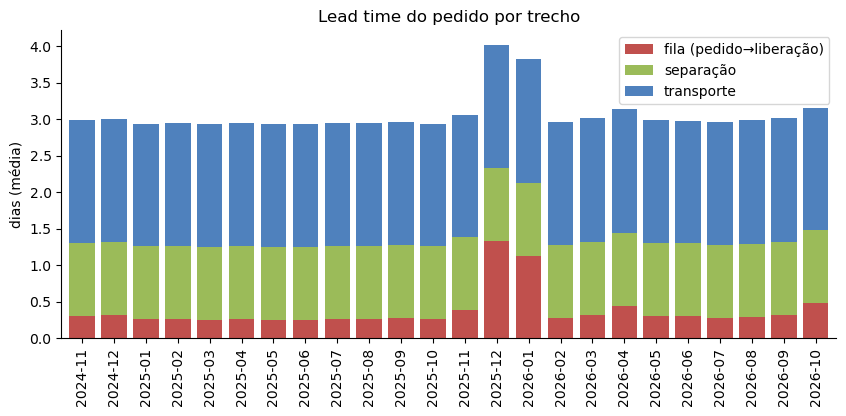

In [7]:
# Barras empilhadas: mostram a composição do lead time do pedido mês a mês.
fig, ax = plt.subplots()
ciclo[["fila_dias", "separacao_dias", "transporte_dias"]].plot.bar(stacked=True, ax=ax, width=0.8,
    color=["#C0504D", "#9BBB59", "#4F81BD"])
ax.set_ylabel("dias (média)"); ax.set_xlabel(""); ax.set_title("Lead time do pedido por trecho")
ax.legend(["fila (pedido→liberação)", "separação", "transporte"])
savefig(fig, "04b_lead_time_trechos")

**Leitura:** separação e transporte ficam constantes; o que explode no pico é a **fila antes
da liberação** (de ~0,3 para >1 dia), justamente quando o volume de linhas/dia sobe. Em dez/2024
(~2.440 linhas/dia) o CD ainda deu conta; em dez/2025 (~2.720 linhas/dia, +12%) não — a capacidade
efetiva de separação está entre esses dois níveis (estimativa a confirmar na simulação).
É sinal de **capacidade de separação saturada** no pico — tema da simulação (Fase 6) e do
dimensionamento de mão de obra (Fase 7).

## 4. Fornecedores: lead time real × nominal, atraso e recusa

In [8]:
po = q("""
    SELECT po.supplier_id, sp.supplier_name, sp.zone, sp.nominal_lead_time_days,
           julianday(po.arrival_date) - julianday(po.order_date)    AS lt_real,
           julianday(po.arrival_date) - julianday(po.expected_date) AS atraso
    FROM fact_purchase_order po JOIN dim_supplier sp ON sp.supplier_id = po.supplier_id
    WHERE po.arrival_date IS NOT NULL""")
rec = q("""SELECT supplier_id, COUNT(*) AS paletes,
                  AVG(status = 'REJECTED') AS recusa,
                  AVG(status = 'ACCEPTED' AND remaining_life_pct < 70) AS aceito_abaixo_70
           FROM fact_receipt GROUP BY supplier_id""")
forn = (po.groupby(["supplier_id", "supplier_name", "zone", "nominal_lead_time_days"])
        .agg(pos=("lt_real", "size"), lt_medio=("lt_real", "mean"), lt_desvio=("lt_real", "std"),
             atraso_medio=("atraso", "mean"), pct_atrasado=("atraso", lambda a: (a > 0).mean()))
        .reset_index().merge(rec, on="supplier_id"))
forn["cv_lead_time"] = forn.lt_desvio / forn.lt_medio   # variabilidade relativa
forn = forn.round(3).sort_values("atraso_medio", ascending=False)
save(forn, "04b_scorecard_fornecedores")
forn[["supplier_name", "zone", "nominal_lead_time_days", "lt_medio", "lt_desvio", "atraso_medio",
      "pct_atrasado", "recusa", "aceito_abaixo_70"]]

,supplier_name,zone,nominal_lead_time_days,lt_medio,lt_desvio,atraso_medio,pct_atrasado,recusa,aceito_abaixo_70
6,Fornecedor 007,dry,9,15.374,6.723,6.374,0.807,0.001,0.000
8,Fornecedor 009,dry,7,12.134,5.220,5.134,0.800,0.000,0.000
10,Fornecedor 011,chilled,3,5.264,2.271,2.264,0.768,0.000,0.000
2,Fornecedor 003,dry,12,12.219,2.216,0.219,0.439,0.000,0.000
16,Fornecedor 017,frozen,4,4.186,0.868,0.186,0.327,0.000,0.000
4,Fornecedor 005,dry,10,10.180,1.824,0.180,0.427,0.000,0.000
12,Fornecedor 013,chilled,4,4.173,0.865,0.173,0.324,0.000,0.000
14,Fornecedor 015,frozen,5,5.171,1.000,0.171,0.369,0.000,0.000
11,Fornecedor 012,chilled,2,2.170,0.560,0.170,0.231,0.000,0.000
15,Fornecedor 016,frozen,3,3.168,0.716,0.168,0.284,0.000,0.000


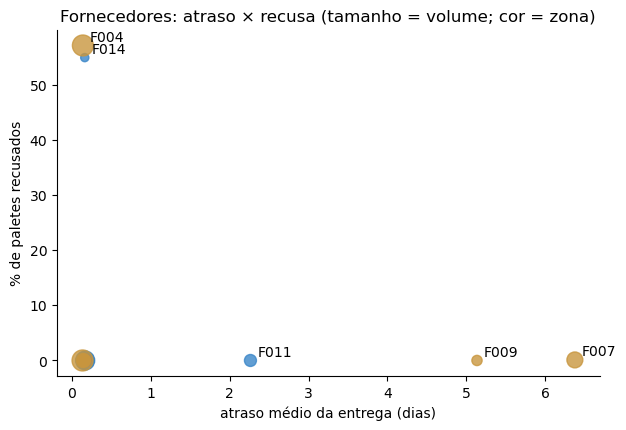

In [9]:
# Dispersão: cruza duas dimensões de risco (atraso × recusa) para cada fornecedor.
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(forn.atraso_medio, 100 * forn.recusa, s=forn.paletes / 60,
           c=forn.zone.map(ZONE_COLORS), alpha=0.8)
for _, r in forn.iterrows():
    if r.atraso_medio > 1 or r.recusa > 0.1:
        ax.annotate(r.supplier_name.replace("Fornecedor ", "F"), (r.atraso_medio, 100 * r.recusa),
                    xytext=(5, 3), textcoords="offset points")
ax.set_xlabel("atraso médio da entrega (dias)"); ax.set_ylabel("% de paletes recusados")
ax.set_title("Fornecedores: atraso × recusa (tamanho = volume; cor = zona)")
savefig(fig, "04b_fornecedores_risco")

**Leitura:**
- **F007, F009 e F011** entregam em média 2–6 dias atrasados, com lead time muito variável →
  exigem estoque de segurança maior (ver 04d) ou renegociação.
- **F004 e F014** têm ~55% dos paletes recusados por vida útil — e, pior, quase todo palete
  **aceito** deles também está abaixo dos 70% exigidos (a regra é furada no recebimento).

## 5. Recebimento: dock-to-stock por horário de chegada

71% dos paletes chegam entre 07h e 11h59


hora,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22
paletes,603.0,3890.0,11261.0,16195.0,16726.0,15512.0,9464.0,5305.0,4387.0,3844.0,3838.0,3474.0,1542.0,507.0,212.0,78.0,40.0,7.0
d2s_mediana,44.0,44.0,50.0,59.0,64.0,66.0,63.0,53.0,49.0,47.0,44.0,47.0,41.0,35.0,35.0,33.0,40.0,29.0


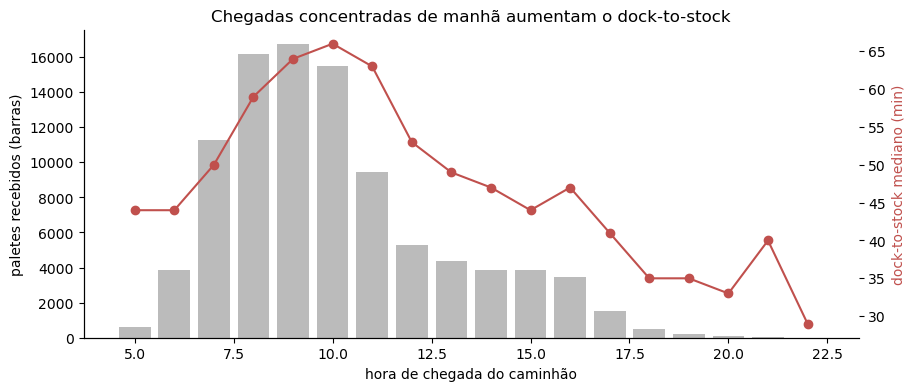

In [10]:
d2s = q("""SELECT CAST(substr(arrival_ts, 12, 2) AS INTEGER) AS hora, zone, dock_to_stock_min
           FROM fact_receipt WHERE status = 'ACCEPTED'""")
por_hora = d2s.groupby("hora").agg(paletes=("dock_to_stock_min", "size"),
                                   d2s_mediana=("dock_to_stock_min", "median")).round(0)
fig, ax1 = plt.subplots()
# Barras (volume) + linha (tempo): mostra se o tempo sobe quando a doca enche.
ax1.bar(por_hora.index, por_hora.paletes, color="#BBBBBB")
ax1.set_ylabel("paletes recebidos (barras)"); ax1.set_xlabel("hora de chegada do caminhão")
ax2 = ax1.twinx(); ax2.plot(por_hora.index, por_hora.d2s_mediana, color="#C0504D", marker="o")
ax2.set_ylabel("dock-to-stock mediano (min)", color="#C0504D")
ax1.set_title("Chegadas concentradas de manhã aumentam o dock-to-stock")
savefig(fig, "04b_dock_to_stock_hora")
share_manha = por_hora.loc[7:11, "paletes"].sum() / por_hora.paletes.sum()
print(f"{share_manha:.0%} dos paletes chegam entre 07h e 11h59")
por_hora.T

**Leitura:** a maior parte dos paletes chega entre 7h e 12h e o dock-to-stock mediano sobe junto
(≈45 min antes das 7h → ≈65 min entre 9h e 11h; à tarde volta a ≈45). Agendamento mais distribuído ao longo do dia reduz fila sem novo investimento.

## 6. Cadeia do frio
Perda por frio (baixas `WRITE_OFF_COLD_CHAIN`) e, no recebimento, exposição acima do limite
na doca e temperatura do caminhão fora da faixa.

Dias com maior perda: ['17/12/2024', '24/12/2024', '23/12/2025', '06/01/2026', '07/01/2026', '08/01/2026', '09/01/2026', '11/01/2026', '13/01/2026', '15/01/2026', '16/01/2026', '17/01/2026', '18/01/2026', '14/04/2026', '20/10/2026']
Jan/2026 concentra 32% de toda a perda por frio dos 24 meses


pct_caminhao_fora_temp        exposicao_media_min       
zone                   chilled frozen             chilled frozen
mes                                                             
2025-09                    0.0   18.7                22.6   24.9
2025-10                    0.0   14.6                20.5   24.4
2025-11                    0.0   23.1                22.0   26.7
2025-12                    0.0   15.5                24.9   34.0
2026-01                    0.0   18.2                42.7   52.9
2026-02                    0.0   14.4                18.8   25.6
2026-03                    0.0   18.7                22.1   28.9
2026-04                    0.0   27.6                25.4   24.9

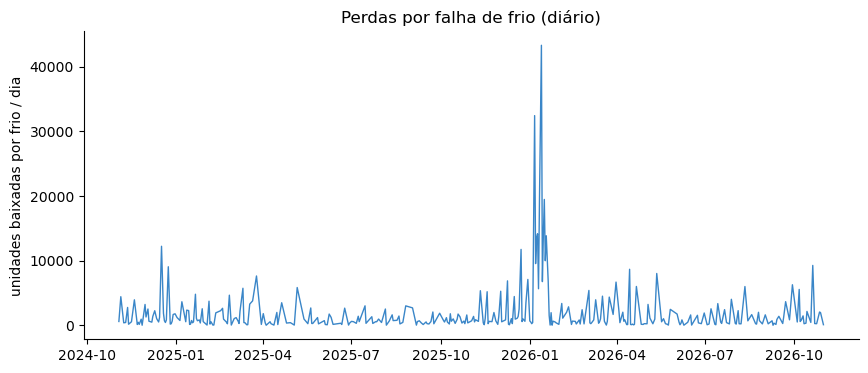

In [11]:
frio_dia = q("""SELECT date_key, SUM(qty_units) AS und FROM fact_movement
                WHERE movement_type = 'WRITE_OFF_COLD_CHAIN' GROUP BY date_key""")
frio_dia["date_key"] = pd.to_datetime(frio_dia.date_key)
# Por mês e zona fria: % de caminhões fora da temperatura e exposição média na doca
exc = q("""SELECT substr(arrival_ts, 1, 7) AS mes, zone,
                  100.0 * AVG(CASE zone WHEN 'chilled' THEN truck_temp_c > 8
                                        ELSE truck_temp_c > -18 END) AS pct_caminhao_fora_temp,
                  AVG(dock_exposure_min) AS exposicao_media_min
           FROM fact_receipt WHERE zone <> 'dry' GROUP BY 1, 2""")

fig, ax = plt.subplots()
# Linha diária: o evento é curto, por isso a granularidade diária (no mensal ele "some").
ax.plot(frio_dia.date_key, frio_dia.und, color="#3A86C8", lw=1)
ax.set_ylabel("unidades baixadas por frio / dia"); ax.set_title("Perdas por falha de frio (diário)")
savefig(fig, "04b_perda_frio_diaria")

top = frio_dia.sort_values("und", ascending=False).head(15).sort_values("date_key")
print("Dias com maior perda:", top.date_key.dt.strftime("%d/%m/%Y").tolist())
janela = frio_dia[(frio_dia.date_key >= "2026-01-01") & (frio_dia.date_key <= "2026-01-31")]
print(f"Jan/2026 concentra {janela.und.sum() / frio_dia.und.sum():.0%} de toda a perda por frio dos 24 meses")
exc.pivot(index="mes", columns="zone").round(1).loc["2025-09":"2026-04"]

**Leitura:**
- A perda por frio é baixa e estável (~0,5–1% do expedido), exceto por uma **janela de ~6 a 18/jan/2026**
  que sozinha responde por **~1/3 da perda dos 24 meses**. Nesse mês a **exposição média na doca
  dobra** (resfriado ~20 → 43 min; congelado ~25 → 53 min), enquanto a temperatura dos caminhões
  não muda: o problema está **dentro do CD** (doca/câmara — ex.: falha de equipamento ou fila de
  putaway no frio), não no transporte.
- Crônico: **15–23% dos caminhões congelados chegam acima de −18 °C** todo mês e, mesmo assim,
  seus paletes são aceitos; e **26% (resfriado) / 61% (congelado)** dos paletes aceitos passam do
  tempo máximo de doca (ver 04a).

## 7. Erros de putaway (paletes guardados no endereço errado)
Um palete com movimento `ADJUST_RELOCATE` teve de ser realocado porque estava no lugar errado.
Taxa por operador e turno do putaway (por mil paletes).

In [12]:
put = q("""
    SELECT r.putaway_shift AS turno, r.putaway_operator_id AS operador, COUNT(*) AS paletes,
           SUM(a.lpn IS NOT NULL) AS erros
    FROM fact_receipt r
    LEFT JOIN (SELECT DISTINCT lpn FROM fact_movement WHERE movement_type = 'ADJUST_RELOCATE') a
           ON a.lpn = r.lpn
    WHERE r.status = 'ACCEPTED'
    GROUP BY 1, 2""")
put["erros_por_mil"] = (1000 * put.erros / put.paletes).round(1)
save(put, "04b_putaway_erros")
put.pivot(index="operador", columns="turno", values="erros_por_mil")

turno,1,2,3
operador,,,
0,2.6,8.4,0.0
1,2.1,9.0,0.0
2,2.2,9.8,0.0
3,15.8,42.1,0.0


**Leitura:** o **turno 2** erra ~4× mais que o turno 1 e o **operador 3** erra 6–7× mais que os
colegas em qualquer turno. São duas causas distintas: condição do turno (iluminação, supervisão,
pressa de fim de recebimento) e necessidade de treinamento/reciclagem individual.
(O turno 3 tem volume desprezível.)

## 8. Ocupação das câmaras e do seco

,ocupacao_media,pico,dias_acima_85,dias_com_transbordo
zone,,,,
chilled,77.4,115.4,126,175
dry,76.5,115.1,227,137
frozen,81.2,110.4,269,134


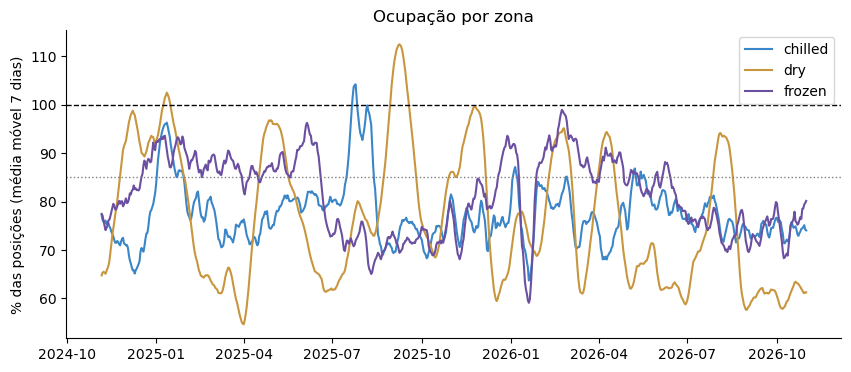

In [13]:
occ = q("SELECT * FROM fact_occupancy_daily")
occ["date_key"] = pd.to_datetime(occ.date_key)
occ["ocupacao"] = 100 * (occ.rack_pallets + occ.overflow_pallets) / occ.rack_positions_total
fig, ax = plt.subplots()
# Linha por zona + referência de 100%: acima dela o CD está usando chão/transbordo.
for z, g in occ.groupby("zone"):
    ax.plot(g.date_key, g.ocupacao.rolling(7).mean(), label=z, color=ZONE_COLORS[z])
ax.axhline(100, color="black", ls="--", lw=1); ax.axhline(85, color="grey", ls=":", lw=1)
ax.set_ylabel("% das posições (média móvel 7 dias)"); ax.legend(); ax.set_title("Ocupação por zona")
savefig(fig, "04b_ocupacao_zona")
resumo_occ = occ.groupby("zone").agg(
    ocupacao_media=("ocupacao", "mean"), pico=("ocupacao", "max"),
    dias_acima_85=("ocupacao", lambda o: (o > 85).sum()),
    dias_com_transbordo=("overflow_pallets", lambda o: (o > 0).sum())).round(1)
resumo_occ

**Leitura:** as três zonas operam com média de 75–80% e **picos acima de 100%** (paletes no chão)
em centenas de dias; acima de ~85% a produtividade de armazenagem cai (mais deslocamento,
mais remanejamento). O congelado é o mais pressionado.

## 9. Acuracidade de inventário (contagem cíclica)

In [14]:
cc = q("SELECT reason_code, COUNT(*) AS n FROM fact_cycle_count GROUP BY 1 ORDER BY n DESC")
cc["pct"] = (100 * cc.n / cc.n.sum()).round(1)
cc

,reason_code,n,pct
0,OK,4252,96.0
1,COUNT_ERROR,114,2.6
2,FOUND_UNEXPECTED,49,1.1
3,MISPLACED,11,0.2
4,NOT_FOUND,5,0.1


Acuracidade de **96%** por endereço contado (meta usual de CD: ≥ 98–99%). Os erros de contagem
dominam; "encontrado sem registro" e "fora do lugar" conversam com os erros de putaway da seção 7.

## Síntese e plano de ação (5W2H)

| # | O quê (What) | Por quê (Why) | Onde | Quem | Quando | Como (How) | Quanto (How much) |
|---|---|---|---|---|---|---|---|
| 1 | Recalcular estoque de segurança por SKU (giro e variabilidade) | Ruptura derruba o In Full do B2B (~23%) | Seco, curva A | Planejamento | Próximo ciclo de S&OP | Modelo da 04d | Sem investimento; ganho em fill rate |
| 2 | Rito de comunicação de promoções (Comercial → Planejamento, D-15) | Mais da metade das promoções não chega ao planejamento | Comercial / PCP | Gerente comercial + PCP | Imediato | Calendário de promoções compartilhado, aceite obrigatório | Baixo |
| 3 | Bloqueio sistêmico de recebimento < 70% de vida útil | F004/F014 entram abaixo da regra | Recebimento | Qualidade + TI WMS | 30 dias | Trava no WMS + reclamação formal ao fornecedor | Baixo |
| 4 | Plano de fornecedores atrasados (F007, F009, F011) | Atraso médio de 2–6 dias | Compras | Compras | 60 dias | Scorecard mensal, SLA contratual, fornecedor alternativo | Negociação |
| 5 | Redistribuir agendamento de docas | Pico 7h–12h eleva dock-to-stock | Docas | Coordenador de recebimento | 30 dias | Janelas por fornecedor, incentivo para tarde | Zero |
| 6 | Tempo máximo de doca no frio (cronômetro + alarme) | 26–61% dos paletes frios acima do limite | Docas frias | Recebimento | Imediato | Prioridade de putaway para frio, paletização na câmara | Baixo |
| 7 | Análise de causa da falha de frio de jan/2026 + recusa de caminhão congelado acima de −18 °C | Evento concentrou ~1/3 da perda do período; 15–23% dos caminhões congelados chegam quentes | Câmaras / transportadora | Manutenção + Qualidade | Imediato | Ishikawa + plano de manutenção preventiva | A orçar |
| 8 | Reciclagem do operador 3 e auditoria do turno 2 | Erro de putaway 4–7× maior | Armazenagem | Supervisor | 15 dias | Treinamento, leitura obrigatória do endereço | Baixo |
| 9 | Capacidade de separação no pico (Natal) | Fila de liberação > 1 dia em dez/jan | Separação | Operações | Antes de nov/2026 | Simulação (Fase 6) e escala de temporários (Fase 7) | A dimensionar |

In [15]:
log(NB, "investigação de KPIs: OTIF por canal/mês, ruptura, promoções, ciclo do pedido, "
        "fornecedores, dock-to-stock, frio, putaway, ocupação, acuracidade (só leitura; sem transformação de dados)")